In [15]:
import sympy as sp

In [16]:
R1, R2, N = sp.symbols('R1 R2 N', positive=True)
i1, r1, K1, h, e, r2, K2, i2, B, D, z, w, C1, C2 = sp.symbols(
    'i1 r1 K1 h e r2 K2 i2 B D z w C1 C2', positive=True)
c1 = C1 * z**w
c2 = C2 *(1 - z)**w
f1 = c1 /(1 + h * c1 * R1 + e * h * c2 * R2)
f2 = c2 /(1 + h * c1 * R1 + e * h * c2 * R2)
intake = (f1 * R1 + e * f2 * R2) 
dR1dt = i1 + r1 * R1 *(1 - R1/K1) - f1 * R1 * N
dR2dt = i2 + r2 * R2 *(1 - R2/K2) - f2 * R2 * N
dNdt = N * (B * intake - D)

In [17]:
sp.diff(intake, z).simplify()

w*(C1*R1*z**(w + 1)*(z - 1)**2*(C1*R1*h*z**w + C2*R2*e*h*(1 - z)**w + 1) - C2*R2*e*z**2*(1 - z)**(w + 1)*(C1*R1*h*z**w + C2*R2*e*h*(1 - z)**w + 1) - h*z*(z - 1)*(C1*R1*z**w + C2*R2*e*(1 - z)**w)*(C1*R1*z**w*(z - 1) + C2*R2*e*z*(1 - z)**w))/(z**2*(z - 1)**2*(C1*R1*h*z**w + C2*R2*e*h*(1 - z)**w + 1)**2)

In [17]:
dintakedz_simp = R1*sp.diff(c1, z) + e*R2*sp.diff(c2, z)
dintakedz_simp.simplify()

w*(C1*R1*z**w*(z - 1) + C2*R2*e*z*(1 - z)**w)/(z*(z - 1))

In [25]:
numer = sp.numer(sp.together(dintakedz_simp))/w
numer

C1*R1*z**w*(1 - z) - C2*R2*e*z*(1 - z)**w

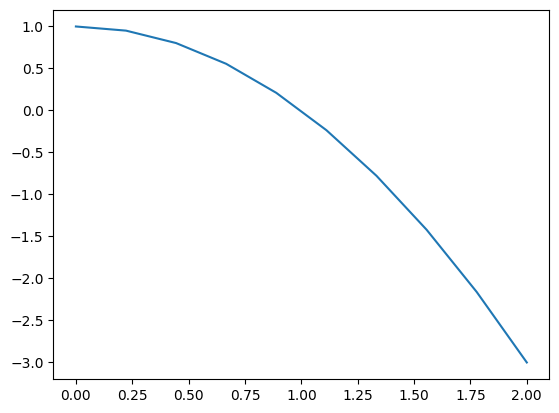

In [1]:
def tradeoff(w, c1):
    return 1 - c1**(1/w)

import matplotlib.pyplot as plt
import numpy as np
plt.plot(np.linspace(0, 2, 10), tradeoff(0.5, np.linspace(0, 2, 10)))

In [1]:
def system_switching(t, vars, cg):
    R1, R2, N = vars
    u = 1/(1-cg.w)
    zopt = (cg.C1 * R1)**u/((cg.e * cg.C2 * R2)**u + (cg.C1 * R1)**u)
    c1 = cg.C1 * zopt**cg.w
    c2 = cg.C2 *(1 - zopt)**cg.w
    f1 = c1 /(1 + cg.h * c1 * R1 + cg.e * cg.h * c2 * R2)
    f2 = c2 /(1 + cg.h * c1 * R1 + cg.e * cg.h * c2 * R2)
    intake = (f1 * R1 + cg.e * f2 * R2) 
    dR1dt = cg.i1 + cg.r1 * R1 *(1 - R1/cg.K1) - f1 * R1 * N
    dR2dt = cg.i2 + cg.r2 * R2 *(1 - R2/cg.K2) - f2 * R2 * N
    dNdt = N * (cg.B * intake - cg.D)
    return [dR1dt, dR2dt, dNdt]

In [2]:
from tools import Config
import numpy as np
from scipy.integrate import solve_ivp

In [3]:
pars = Config(dict(C1 = 5, C2 = 5, h = 1, B = 0.1, K1 = 1, K2 = 1, i1 = 0, i2 = 0, r1 = 1, r2 = 0.25, D = 0.05, e = 1, w = 0.8))
system_switching(0, [1, 1, 1], pars)

[-0.4258544361461612, -0.4258544361461612, 0.03517088722923224]

In [12]:
init = [0.1, 0.1, 0.1]
sol = solve_ivp(lambda t, y: system_switching(t, y, pars), t_span = [0, 1000], y0 =init, t_eval = np.linspace(0, 1000, 6000))

/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_71655/3100993672.py:4: RuntimeWarning: invalid value encountered in scalar power
  zopt = (cg.C1 * R1)**u/((cg.e * cg.C2 * R2)**u + (cg.C1 * R1)**u)


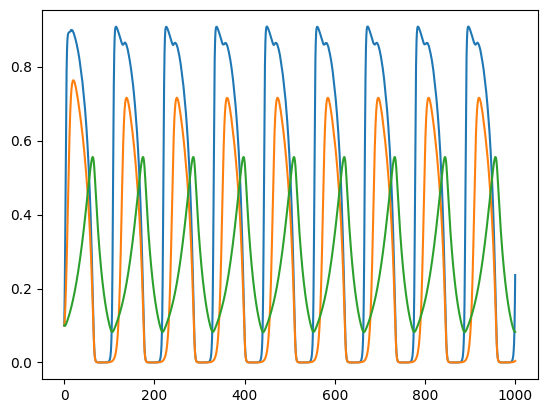

In [13]:
import matplotlib.pylab as plt
plt.plot(sol.t, sol.y[0], label = 'R1')
plt.plot(sol.t, sol.y[1], label = 'R2')
plt.plot(sol.t, sol.y[2], label = 'N')

In [41]:
from jitcdde import jitcdde, y, t
import numpy as np
import matplotlib.pyplot as plt
from tools import Config
import symengine as si


In [42]:
tau = 15
n = 10
beta = 0.25
gamma = 0.1

In [43]:
def f():
    return [0.25 * y(0,t-15) / (1 + y(0,t-15)**10) - 0.1*y(0, t) ]
ff = f()
DDE = jitcdde(ff)

In [46]:
DDE.constant_past([1.0])

In [47]:
data = []
for time in np.arange(DDE.t, DDE.t+10000, 10):
	data.append( DDE.integrate(time) )

Using default integration parameters.


/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_97539/361574611.py:3: UserWarning: You did not explicitly handle initial discontinuities. Proceed only if you know what you are doing. This is only fine if you somehow chose your initial past such that the derivative of the last anchor complies with the DDE. In this case, you can set the attribute `initial_discontinuities_handled` to `True` to suppress this warning. See https://jitcdde.rtfd.io/#discontinuities for details.
  data.append( DDE.integrate(time) )


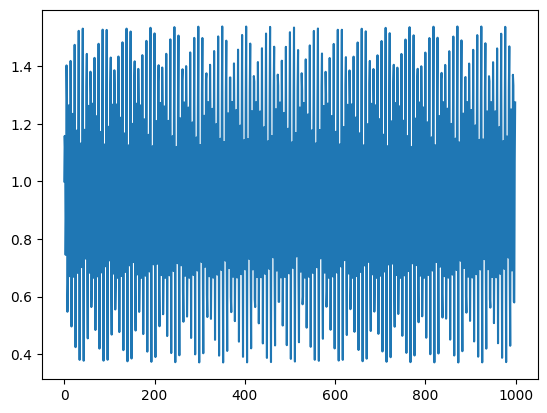

In [25]:
plt.plot(data)

In [82]:
def foo(cg):
    dAdt = cg.q * cg.SJ * y(0, t - cg.TJ) * si.exp(-y(0, t - cg.TJ)/cg.A0) - cg.dA * y(0, t)
    return [dAdt]

def foo2(cg):
    RA   = cg.q * y(0, t - cg.TJ) * si.exp(-y(0, t - cg.TJ)/cg.A0) * cg.SJ
    DA   = cg.dA * y(0, t)
    RJ   = cg.q * y(0, t - cg.TJ) * si.exp(-y(0, t - cg.TJ)/cg.A0) 
    MJ = cg.q * y(0, t - cg.TJ) * si.exp(-y(0, t - cg.TJ)/cg.A0) * cg.SJ
    DJ = cg.dJ * y(1, t)
    dAdt = RA - DA
    dJdt = RJ - MJ - DJ
    return [dAdt, dJdt]
pp = Config(dict(q = 8.5, SJ = 0.9, TJ = 15.6, A0 = 600, dA = 0.27))
pp2 = Config(dict(q = 8.5, SJ = 0.9, TJ = 15.6, A0 = 600, dA = 0.27, dJ = - 15.6 * np.log(0.9)))
foop = foo(pp)
foop2 = foo2(pp2)

Generating, compiling, and loading C code.


ld: warning: duplicate -rpath '/Users/phuongnguyen/miniconda3/lib' ignored


Using default integration parameters.


/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_97539/3736405596.py:6: UserWarning: You did not explicitly handle initial discontinuities. Proceed only if you know what you are doing. This is only fine if you somehow chose your initial past such that the derivative of the last anchor complies with the DDE. In this case, you can set the attribute `initial_discontinuities_handled` to `True` to suppress this warning. See https://jitcdde.rtfd.io/#discontinuities for details.
  data.append( DDE.integrate(time) )
/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_97539/3736405596.py:6: UserWarning: The target time is smaller than the current time. No integration step will happen. The returned state will be extrapolated from the interpolating Hermite polynomial for the last integration step. You may see this because you try to integrate backwards in time, in which case you did something wrong. You may see this just because your sampling step is small, in which case there is

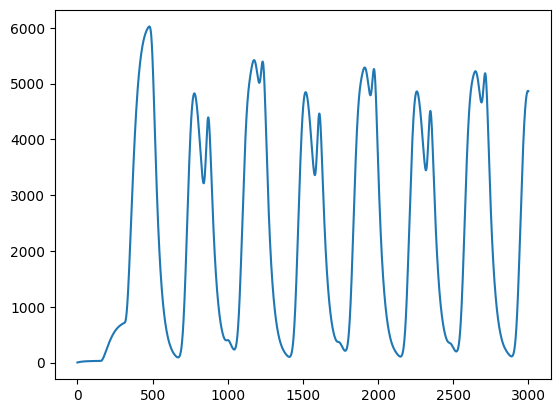

In [83]:
DDE = jitcdde(foop)
DDE.constant_past([1])
data = []
tseries = np.arange(DDE.t, DDE.t+300, 0.1)
for time in tseries:
	data.append( DDE.integrate(time) )
plt.plot(data)

Generating, compiling, and loading C code.


ld: warning: duplicate -rpath '/Users/phuongnguyen/miniconda3/lib' ignored


Using default integration parameters.


/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_97539/2485219502.py:6: UserWarning: You did not explicitly handle initial discontinuities. Proceed only if you know what you are doing. This is only fine if you somehow chose your initial past such that the derivative of the last anchor complies with the DDE. In this case, you can set the attribute `initial_discontinuities_handled` to `True` to suppress this warning. See https://jitcdde.rtfd.io/#discontinuities for details.
  data.append( DDE2.integrate(time) )
/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_97539/2485219502.py:6: UserWarning: The target time is smaller than the current time. No integration step will happen. The returned state will be extrapolated from the interpolating Hermite polynomial for the last integration step. You may see this because you try to integrate backwards in time, in which case you did something wrong. You may see this just because your sampling step is small, in which case there i

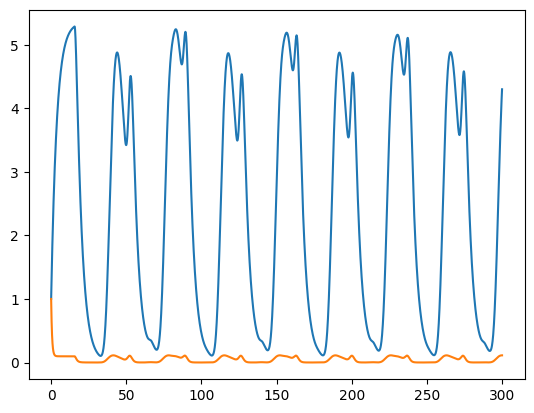

In [86]:
DDE2 = jitcdde(foop2)
DDE2.constant_past([1000, 1000])
data = []
tseries = np.arange(DDE2.t, DDE2.t+300, 0.1)
for time in tseries:
	data.append( DDE2.integrate(time) )
data = np.array(data)
plt.plot(tseries, data[:, 0]/1000, label = 'A')
plt.plot(tseries, data[:, 1]/1000, label = 'J')

In [2]:
from jitcdde import jitcdde, y, t
import numpy as np
import matplotlib.pyplot as plt
from tools import Config
import symengine as si
from scipy.integrate import solve_ivp

In [56]:
def foo():
    dH2dt = pp.Q * y(0, t - pp.tauH) * si.exp(-y(0, t - pp.tauH)/pp.H0) - pp.sigma2 * y(0, t)
    return [dH2dt]

def foo1(t, vars, cg):
    nb_jul = len(vars)
    dH11dt = cg.Q * vars[-1] * np.exp(-vars[-1]/cg.H0) - (cg.sigma1 + cg.thetaH) * vars[0]
    ode = [dH11dt]
    for i in range(1, nb_jul - 1):
        dd = cg.thetaH * (vars[i-1] - vars[i]) - cg.sigma1 * vars[i]
        ode.append(dd)
    dH2dt = cg.thetaH * vars[-2] - cg.sigma2 * vars[-1]
    ode.append(dH2dt)
    return ode

In [74]:
pp = Config(dict(Q = 8.5, H0 = 600, sigma1 = 0.07, sigma2 = 0.2, tauH = 17))
pp1 = Config(dict(Q = 8.5, H0 = 600, sigma1 = 0.07, sigma2 = 0.2, tauH = 17))
f = foo()


Generating, compiling, and loading C code.


ld: warning: duplicate -rpath '/Users/phuongnguyen/miniconda3/lib' ignored


Using default integration parameters.


/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_1611/845231222.py:14: UserWarning: You did not explicitly handle initial discontinuities. Proceed only if you know what you are doing. This is only fine if you somehow chose your initial past such that the derivative of the last anchor complies with the DDE. In this case, you can set the attribute `initial_discontinuities_handled` to `True` to suppress this warning. See https://jitcdde.rtfd.io/#discontinuities for details.
  data.append( DDE.integrate(time) )
/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_1611/845231222.py:14: UserWarning: The target time is smaller than the current time. No integration step will happen. The returned state will be extrapolated from the interpolating Hermite polynomial for the last integration step. You may see this because you try to integrate backwards in time, in which case you did something wrong. You may see this just because your sampling step is small, in which case there is n

Text(0.5, 1.0, 'ODE')

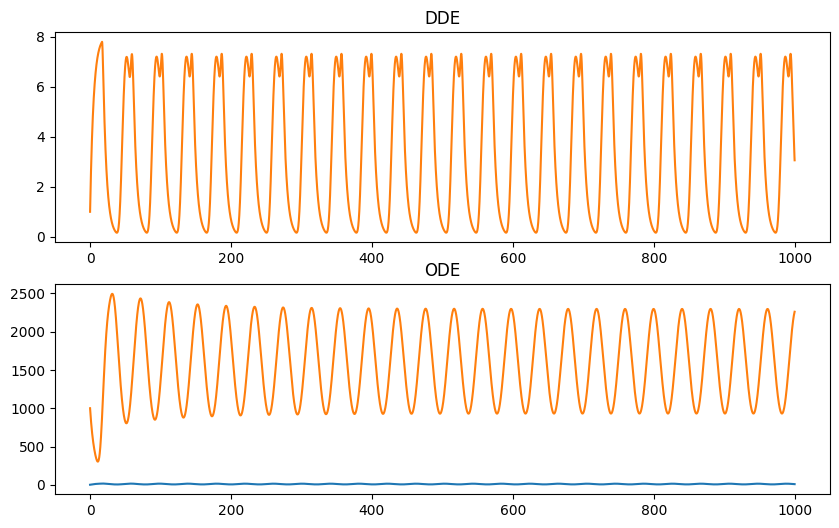

In [75]:
DDE = jitcdde(f)
DDE.constant_past([1000])
nbjul = 20
y0 = [50]*nbjul + [1000]
#y0 = [330]*nbjul + [1000]
pp1.thetaH = (1/pp1.tauH) * nbjul

f1 = lambda t, vars: foo1(t, vars, pp1)
ode = solve_ivp(f1, t_span = [0, 1000], 
                y0 = y0, t_eval = np.linspace(0, 1000, 6000))
data = []
tseries = np.arange(DDE.t, DDE.t+1000, 0.1)
for time in tseries:
    data.append( DDE.integrate(time) )
data = np.array(data)
fig, axes = plt.subplots(2, 1, figsize = (10, 6))
axes[0].plot(tseries, data/1000, color = 'C1')
axes[0].set_title('DDE')
axes[1].plot(ode.t, ode.y[0:-1].sum(axis = 0)/1000, label = 'H1')
axes[1].plot(ode.t, ode.y[-1], label = 'H2', color = 'C1')
axes[1].set_title('ODE')